# Oracle Construction — Bit-Flip Oracle — Qiskit Notebook

**Primitive:** Bit-flip (XOR-style) oracle `U_f|x>|y> = |x>|y XOR f(x)>` implemented with a
dedicated ancilla/output qubit, for the single-marked-item function `f(x) = 1` iff
`x == TARGET_INT`, else `0`. This is the classic Deutsch-Jozsa / Bernstein-Vazirani style
oracle construction, distinct from the phase oracle (which encodes the result as a `-1`
phase on the input register with no extra qubit).

## SETUP (must match the CUDA-Q notebook exactly)
| Parameter | Value |
|---|---|
| N_QUBITS (input register) | 3  (indices q0..q2, q0 = LSB) |
| ANCILLA_QUBIT | q3  (the dedicated output/target qubit, initialized to \|0>) |
| TOTAL_QUBITS | 4 |
| TARGET_INT | 5  (marked input pattern, qubit 0 = LSB) |
| SHOTS | 10000 |
| SEED | 42 |
| QUBIT ORDERING CONTRACT | qubit 0 = **rightmost** bit in every printed bitstring (Qiskit's native convention — no reversal needed in this notebook) |
| GLOBAL PHASE CONVENTION | normalize so the first amplitude with `abs(amp) > 1e-9`, taken in ascending bitstring order, is rotated to be real and positive |
| Basis ordering for matrices | `{|0000>, |0001>, ..., |1111>}` ascending binary order (16-dim, 3 input qubits + 1 ancilla) |

## Theory recap

A bit-flip oracle for boolean function `f` acts on an `(n+1)`-qubit register as

`U_f |x>|y> = |x> |y XOR f(x)>`

For the single-marked-item function used here, `f(x) = 1` iff `x == TARGET_INT`, this is
built from ordinary gates exactly like the phase-oracle's multi-controlled-X, but **without**
the `H`-sandwich trick — the ancilla is flipped directly, not phase-kicked:

```
for each qubit q where bit q of TARGET_INT is 0:
    X(q)                                    # temporarily remap TARGET_INT onto all-ones
MCX(controls = q_0..q_{n-1}, target = ANCILLA_QUBIT)   # flip the ancilla iff input == all-ones (i.e. == TARGET_INT)
for each qubit q where bit q of TARGET_INT is 0:
    X(q)                                    # undo the temporary remap
```

With `N_QUBITS = 3` controls, the middle gate is a **3-controlled-X** (a generalized
Toffoli, `Qiskit`'s `mcx` handles any number of controls).

**Test harness:** to make the oracle's effect visible, this notebook prepares a uniform
superposition on the 3 input qubits (ancilla stays `|0>`) before applying the oracle. Only
the 3 gate lines above are the oracle itself; the initial `H` layer is test scaffolding.

**Hand-verified structure:** after the oracle, exactly **8 of the 16** possible 4-qubit
basis states have nonzero amplitude (one for every input `x`, paired with the correct
`f(x)` on the ancilla) — the other 8 (where the ancilla disagrees with `f(x)` for that `x`)
have probability exactly `0`. All 8 reachable outcomes are equally likely at `1/8` each.
Unlike the phase oracle, this histogram is **not** flat over all 16 outcomes — it is flat
only over the 8 physically reachable ones, which makes the effect of the oracle directly
visible in the measured probabilities (no phase-inspection needed).

## Ordering-convention warning

Qiskit already indexes statevector amplitudes, `Operator` matrices, and measurement `counts`
keys with **qubit 0 as the least-significant (rightmost) bit** — no reversal is required in
this notebook. The CUDA-Q companion notebook indexes qubit 0 as the **most-significant
(leftmost) bit** internally and must explicitly reverse every bitstring to match this
convention.

**Run all cells top to bottom.**


In [1]:
# Install cell
# Exact package names: `qiskit` (core) + `qiskit-aer` (the high-performance simulator backend)
# + `pylatexenc` (needed by circuit.draw(output="mpl") to render gate labels).
# Tested against the current stable Qiskit 1.x / Aer 0.x release line.
!pip install -q qiskit qiskit-aer pylatexenc


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 2.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 34.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 39.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 33.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 2.2 MB/s eta 0:00:00


In [2]:
# Imports + constants
import numpy as np
from math import pi

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, Operator
import matplotlib.pyplot as plt

N_QUBITS = 3          # input register size
ANCILLA_QUBIT = 3      # dedicated output/target qubit index
TOTAL_QUBITS = N_QUBITS + 1
TARGET_INT = 5          # marked input pattern (qubit 0 = LSB)
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "bitflip_oracle"

print("N_QUBITS      =", N_QUBITS)
print("ANCILLA_QUBIT =", ANCILLA_QUBIT)
print("TOTAL_QUBITS  =", TOTAL_QUBITS)
print("TARGET_INT    =", TARGET_INT, "-> binary (q2 q1 q0) =", format(TARGET_INT, f'0{N_QUBITS}b'))
print("SHOTS         =", SHOTS)
print("SEED          =", SEED)


N_QUBITS      = 3
ANCILLA_QUBIT = 3
TOTAL_QUBITS  = 4
TARGET_INT    = 5 -> binary (q2 q1 q0) = 101
SHOTS         = 10000
SEED          = 42


In [3]:
# Build the circuit gate-by-gate
qc = QuantumCircuit(TOTAL_QUBITS, name="BitFlipOracleDemo")

# --- test harness: uniform superposition on the input register only (ancilla stays |0>) ---
for q in range(N_QUBITS):
    qc.h(q)  # equal superposition over all 2^N_QUBITS input patterns, so the oracle's flip is visible

qc.barrier(label="oracle start")

# --- bit-flip oracle marking TARGET_INT ---
zero_bit_qubits = [q for q in range(N_QUBITS) if not ((TARGET_INT >> q) & 1)]
for q in zero_bit_qubits:
    qc.x(q)  # temporarily remap the TARGET_INT pattern onto the all-ones pattern

qc.mcx(list(range(N_QUBITS)), ANCILLA_QUBIT)  # generalized Toffoli: flips the ancilla iff input == all-ones (== TARGET_INT)

for q in zero_bit_qubits:
    qc.x(q)  # undo the temporary remap

qc.barrier(label="oracle end")

print(qc)
print("\nQubits X'd before/after the MCX (bits of TARGET_INT equal to 0):", zero_bit_qubits)


     ┌───┐ oracle start                 oracle end 
q_0: ┤ H ├──────░──────────────■────────────░──────
     ├───┤      ░       ┌───┐  │  ┌───┐     ░      
q_1: ┤ H ├──────░───────┤ X ├──■──┤ X ├─────░──────
     ├───┤      ░       └───┘  │  └───┘     ░      
q_2: ┤ H ├──────░──────────────■────────────░──────
     └───┘      ░            ┌─┴─┐          ░      
q_3: ───────────░────────────┤ X ├──────────░──────
                ░            └───┘          ░      

Qubits X'd before/after the MCX (bits of TARGET_INT equal to 0): [1]


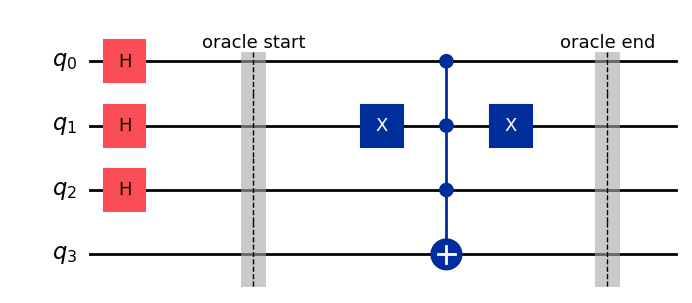

In [4]:
# Draw the circuit with matplotlib and save it
fig = qc.draw(output="mpl", style={"name": "iqp"})
fig.savefig(f"{TOPIC_SLUG}_qiskit_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# Explicit matrix representation, built two independent ways, cross-checked

def h_matrix_full(n, q):
    # Full 2^n x 2^n matrix for H acting on qubit q (qiskit convention: qubit 0 = rightmost/LSB)
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        bit = (idx >> q) & 1
        idx0 = idx & ~(1 << q)
        idx1 = idx | (1 << q)
        if bit == 0:
            M[idx0, idx] += 1/np.sqrt(2)
            M[idx1, idx] += 1/np.sqrt(2)
        else:
            M[idx1, idx] += -1/np.sqrt(2)
            M[idx0, idx] += 1/np.sqrt(2)
    return M

def x_matrix_full(n, q):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        M[idx ^ (1 << q), idx] = 1
    return M

def mcx_matrix_full(n, controls, target):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        if all((idx >> c) & 1 for c in controls):
            M[idx ^ (1 << target), idx] = 1
        else:
            M[idx, idx] = 1
    return M

print("Single-qubit H matrix (any qubit), rounded to 4 decimals:")
print(np.round((1/np.sqrt(2)) * np.array([[1, 1], [1, -1]]), 4))

print("\nOracle-only matrix is a PERMUTATION matrix (unlike the phase oracle's diagonal matrix):")
print("it swaps the |TARGET_INT>|0> <-> |TARGET_INT>|1> basis states and leaves everything else fixed.")

# (a) Hand-built full unitary (H layer + oracle): multiply gate matrices in circuit order
U_hand = np.eye(2**TOTAL_QUBITS, dtype=complex)
for q in range(N_QUBITS):
    U_hand = h_matrix_full(TOTAL_QUBITS, q) @ U_hand
for q in zero_bit_qubits:
    U_hand = x_matrix_full(TOTAL_QUBITS, q) @ U_hand
U_hand = mcx_matrix_full(TOTAL_QUBITS, list(range(N_QUBITS)), ANCILLA_QUBIT) @ U_hand
for q in zero_bit_qubits:
    U_hand = x_matrix_full(TOTAL_QUBITS, q) @ U_hand

# (b) Framework operator extraction (Qiskit's own Operator class from the circuit)
U_qiskit = Operator(qc).data

max_matrix_diff = np.max(np.abs(U_hand - U_qiskit))
print(f"\nMax |difference| between hand-built matrix and qiskit.quantum_info.Operator: {max_matrix_diff:.3e}")
assert max_matrix_diff < 1e-8, "Hand-built matrix and Qiskit Operator disagree!"
print("Full 16x16 unitary matrices MATCH (both methods agree).")

# Verify JUST the oracle sub-circuit is the expected permutation: |TARGET_INT>|0> <-> |TARGET_INT>|1>, identity elsewhere
U_oracle_only = np.eye(2**TOTAL_QUBITS, dtype=complex)
for q in zero_bit_qubits:
    U_oracle_only = x_matrix_full(TOTAL_QUBITS, q) @ U_oracle_only
U_oracle_only = mcx_matrix_full(TOTAL_QUBITS, list(range(N_QUBITS)), ANCILLA_QUBIT) @ U_oracle_only
for q in zero_bit_qubits:
    U_oracle_only = x_matrix_full(TOTAL_QUBITS, q) @ U_oracle_only

ideal_oracle = np.eye(2**TOTAL_QUBITS, dtype=complex)
idx_y0 = TARGET_INT               # ancilla bit (bit ANCILLA_QUBIT) = 0
idx_y1 = TARGET_INT | (1 << ANCILLA_QUBIT)   # ancilla bit = 1
ideal_oracle[[idx_y0, idx_y1]] = ideal_oracle[[idx_y1, idx_y0]]  # swap those two rows -> permutation

max_oracle_diff = np.max(np.abs(U_oracle_only - ideal_oracle))
print(f"Max |difference| between oracle-only matrix and ideal permutation: {max_oracle_diff:.3e}")
assert max_oracle_diff < 1e-8, "Oracle sub-circuit does not match the ideal bit-flip permutation!"
print("Oracle-only matrix MATCHES the ideal bit-flip permutation operator.")


Single-qubit H matrix (any qubit), rounded to 4 decimals:
[[ 0.7071  0.7071]
 [ 0.7071 -0.7071]]

Oracle-only matrix is a PERMUTATION matrix (unlike the phase oracle's diagonal matrix):
it swaps the |TARGET_INT>|0> <-> |TARGET_INT>|1> basis states and leaves everything else fixed.

Max |difference| between hand-built matrix and qiskit.quantum_info.Operator: 2.274e-16
Full 16x16 unitary matrices MATCH (both methods agree).
Max |difference| between oracle-only matrix and ideal permutation: 0.000e+00
Oracle-only matrix MATCHES the ideal bit-flip permutation operator.


In [6]:
# Exact statevector: extract, apply global-phase normalization, print amplitudes + probabilities
qc_state_only = QuantumCircuit(TOTAL_QUBITS)
qc_state_only.compose(qc, inplace=True)  # same gates, no measurements yet

sv = Statevector.from_instruction(qc_state_only)
amps = sv.data.copy()

# GLOBAL PHASE CONVENTION: first amplitude with abs(amp) > 1e-9, ascending bitstring order, made real & positive
for idx in range(len(amps)):
    if abs(amps[idx]) > 1e-9:
        phase = np.angle(amps[idx])
        amps = amps * np.exp(-1j*phase)
        break

print("Qiskit convention: qubit 0 = rightmost bit -> NO reversal needed for these amplitudes.\n")
print(f"{'bitstring (q3 q2 q1 q0)':26s} {'amplitude':22s} {'probability':12s}")
QISKIT_PROBS_EXACT = {}
for idx in range(2**TOTAL_QUBITS):
    bitstring = format(idx, f'0{TOTAL_QUBITS}b')
    amp = amps[idx]
    prob = abs(amp)**2
    QISKIT_PROBS_EXACT[bitstring] = prob
    marker = "  <-- f(x)=1 (input == TARGET_INT, ancilla flipped)" if prob > 1e-9 and ((idx >> ANCILLA_QUBIT) & 1) else ""
    print(f"|{bitstring}>{'':16s}{amp.real:+.6f}{amp.imag:+.6f}j    {prob:.6f}{marker}")

print("\nProbabilities sum to:", sum(QISKIT_PROBS_EXACT.values()))


Qiskit convention: qubit 0 = rightmost bit -> NO reversal needed for these amplitudes.

bitstring (q3 q2 q1 q0)    amplitude              probability 
|0000>                +0.353553+0.000000j    0.125000
|0001>                +0.353553-0.000000j    0.125000
|0010>                +0.353553+0.000000j    0.125000
|0011>                +0.353553+0.000000j    0.125000
|0100>                +0.353553-0.000000j    0.125000
|0101>                -0.000000-0.000000j    0.000000
|0110>                +0.353553+0.000000j    0.125000
|0111>                +0.353553-0.000000j    0.125000
|1000>                -0.000000+0.000000j    0.000000
|1001>                -0.000000+0.000000j    0.000000
|1010>                +0.000000-0.000000j    0.000000
|1011>                +0.000000+0.000000j    0.000000
|1100>                +0.000000-0.000000j    0.000000
|1101>                +0.353553+0.000000j    0.125000  <-- f(x)=1 (input == TARGET_INT, ancilla flipped)
|1110>                +0.000000+0.000000j 

### Ordering-fix note (Qiskit)

**No bit reversal was applied in this notebook.** Qiskit's `Statevector`, `Operator`, and
measurement `counts` all natively index qubit 0 as the least-significant (rightmost) bit of
every printed bitstring — this already matches the QUBIT ORDERING CONTRACT declared in the
setup, so the amplitudes and probabilities above are used as-is. The leftmost character of
each printed 4-bit string is the ancilla (`q3`); the rightmost three characters are the input
register (`q2 q1 q0`).

Contrast this with the CUDA-Q notebook, where `cudaq.get_state()` and `cudaq.sample()` index
qubit 0 as the *most-significant* (leftmost) bit, requiring an explicit reversal step before
its results can be compared to this notebook's.


In [7]:
# Measurement: add measurements, sample with the shared SEED/SHOTS, get counts -> probabilities
qc_meas = QuantumCircuit(TOTAL_QUBITS, TOTAL_QUBITS)
qc_meas.compose(qc, inplace=True)
qc_meas.measure(range(TOTAL_QUBITS), range(TOTAL_QUBITS))

sim = AerSimulator(seed_simulator=SEED)
qc_meas_t = transpile(qc_meas, sim)
job = sim.run(qc_meas_t, shots=SHOTS, seed_simulator=SEED)
counts = job.result().get_counts()

# counts keys are already in "qubit 0 = rightmost" format -> no reordering needed
QISKIT_PROBS_SAMPLED = {format(idx, f'0{TOTAL_QUBITS}b'): 0.0 for idx in range(2**TOTAL_QUBITS)}
for bitstring, count in counts.items():
    QISKIT_PROBS_SAMPLED[bitstring] = count / SHOTS

print("Sampled probabilities (from", SHOTS, "shots, seed =", SEED, "), nonzero entries only:")
for bitstring in sorted(QISKIT_PROBS_SAMPLED):
    if QISKIT_PROBS_SAMPLED[bitstring] > 0:
        print(f"|{bitstring}>   {QISKIT_PROBS_SAMPLED[bitstring]:.4f}")


Sampled probabilities (from 10000 shots, seed = 42 ), nonzero entries only:
|0000>   0.1256
|0001>   0.1199
|0010>   0.1226
|0011>   0.1240
|0100>   0.1278
|0110>   0.1296
|0111>   0.1277
|1101>   0.1228


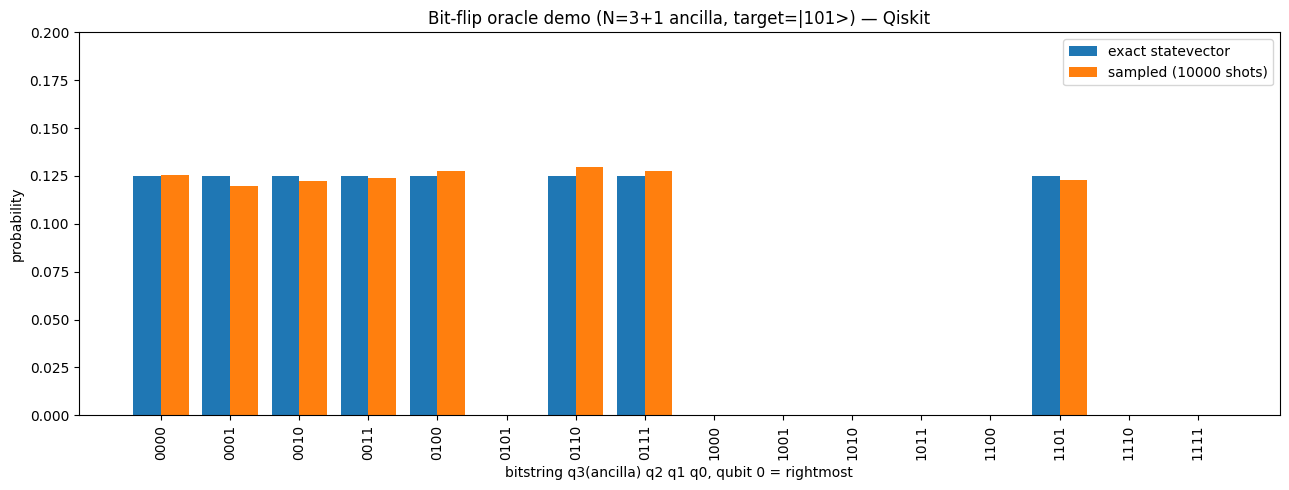

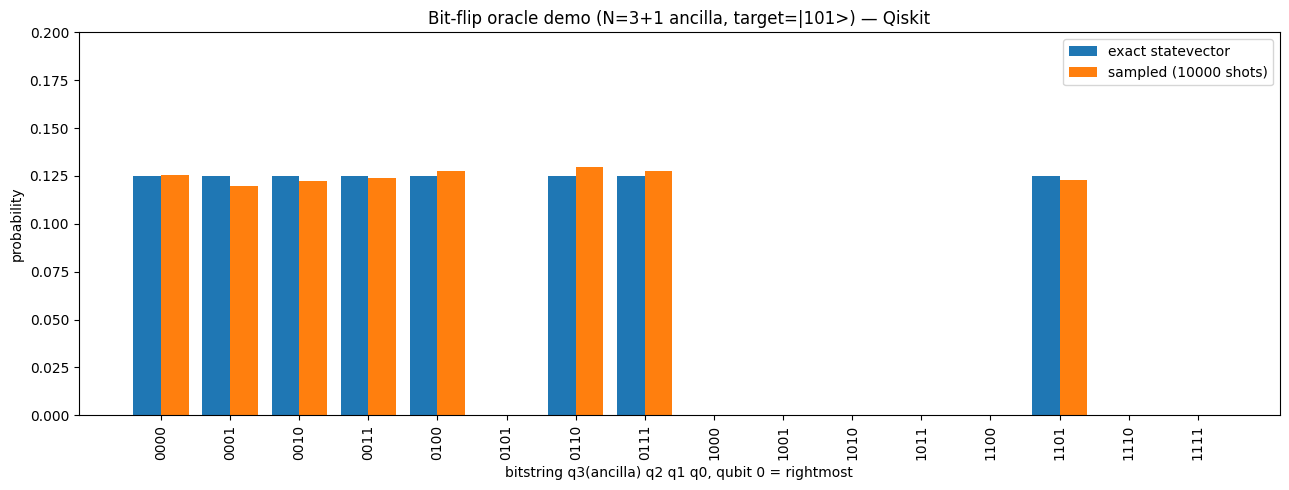

In [8]:
# Histogram: matplotlib bar chart, saved to file
bitstrings_sorted = sorted(QISKIT_PROBS_EXACT.keys())
exact_vals = [QISKIT_PROBS_EXACT[b] for b in bitstrings_sorted]
sampled_vals = [QISKIT_PROBS_SAMPLED[b] for b in bitstrings_sorted]

fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(bitstrings_sorted))
width = 0.4
ax.bar(x - width/2, exact_vals, width, label="exact statevector", color="#1f77b4")
ax.bar(x + width/2, sampled_vals, width, label=f"sampled ({SHOTS} shots)", color="#ff7f0e")
ax.set_xticks(x)
ax.set_xticklabels(bitstrings_sorted, rotation=90)
ax.set_xlabel("bitstring q3(ancilla) q2 q1 q0, qubit 0 = rightmost")
ax.set_ylabel("probability")
ax.set_title(f"Bit-flip oracle demo (N={N_QUBITS}+1 ancilla, target=|{format(TARGET_INT, f'0{N_QUBITS}b')}>) — Qiskit")
ax.set_ylim(0, 0.2)
ax.legend()
fig.tight_layout()
fig.savefig(f"{TOPIC_SLUG}_qiskit_histogram.png", dpi=150, bbox_inches="tight")
fig


In [9]:
# Resource counts
print("Circuit depth:", qc.depth())
print("Gate counts:", dict(qc.count_ops()))


Circuit depth: 4
Gate counts: {'h': 3, 'barrier': 2, 'x': 2, 'mcx': 1}


### Convention notes (plain text summary)

- **Bit-order convention:** qubit 0 = rightmost character of every bitstring. Qiskit uses
  this natively; **no reversal applied** in this notebook.
- **Global phase convention:** the exact statevector was multiplied by `exp(-i*phase)` where
  `phase` is the angle of the first amplitude (ascending bitstring order) with magnitude
  `> 1e-9`, so that amplitude is real and positive.
- **Basis ordering for all matrices:** ascending binary order `|0000> ... |1111>` (4 qubits:
  3 input + 1 ancilla).
- **Why only 8 of 16 outcomes are possible:** the oracle is a permutation, not a diagonal
  matrix — it deterministically pairs every input `x` with its correct `f(x)` on the
  ancilla, so exactly half of the 16-dimensional basis is reachable, each with probability
  `1/8`.


In [10]:
# Final result: exact-statevector-derived probability dictionary
# (used for the cross-notebook diff-check, since it is deterministic and RNG-independent --
#  unlike the finite-shot counts, which depend on each framework's own internal RNG stream
#  and will NOT exactly agree bit-for-bit even with a matching SEED value)
QISKIT_RESULT = {b: QISKIT_PROBS_EXACT[b] for b in sorted(QISKIT_PROBS_EXACT)}
print("QISKIT_RESULT (nonzero entries) =")
for b, p in QISKIT_RESULT.items():
    if p > 1e-9:
        print(f"  '{b}': {p:.6f}")


QISKIT_RESULT (nonzero entries) =
  '0000': 0.125000
  '0001': 0.125000
  '0010': 0.125000
  '0011': 0.125000
  '0100': 0.125000
  '0110': 0.125000
  '0111': 0.125000
  '1101': 0.125000


In [11]:
# Diff-check block (run AFTER also running the CUDA-Q notebook and pasting its CUDAQ_RESULT below)
# Hand-computed expected result for sanity-checking: 8 reachable outcomes at 1/8 each, 8 at 0.
HAND_COMPUTED_EXPECTED = {format(i, f'0{TOTAL_QUBITS}b'): 0.0 for i in range(2**TOTAL_QUBITS)}
for x in range(2**N_QUBITS):
    fx = 1 if x == TARGET_INT else 0
    idx = x | (fx << ANCILLA_QUBIT)
    HAND_COMPUTED_EXPECTED[format(idx, f'0{TOTAL_QUBITS}b')] = 1 / (2**N_QUBITS)

max_delta_vs_hand = max(abs(QISKIT_RESULT[b] - HAND_COMPUTED_EXPECTED[b]) for b in QISKIT_RESULT)
print("Max delta between QISKIT_RESULT and hand-computed expected:", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-3

# CUDAQ_RESULT = { ... }  # <- paste the dict printed at the end of the CUDA-Q notebook here
# max_delta = max(abs(QISKIT_RESULT[b] - CUDAQ_RESULT[b]) for b in QISKIT_RESULT)
# print("Max probability delta between QISKIT_RESULT and CUDAQ_RESULT:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q bit-flip-oracle results disagree beyond tolerance!"


Max delta between QISKIT_RESULT and hand-computed expected: 2.220446049250313e-16
